# Матрица ошибок — вариант 20: автоотбор резюме
**Положительный класс («да»):** кандидат подходит.

| TP | FN | FP | TN | Сдвиг порога |
|---|---|---|---|---|
| 139 | 61 | 133 | 667 | 46 FN → TP, 171 TN → FP |

Всего 1000 резюме: 200 подходящих и 800 неподходящих. Все метрики округлены до трёх знаков.

## 1. Матрица ошибок 2×2 (строки — факт, столбцы — прогноз)

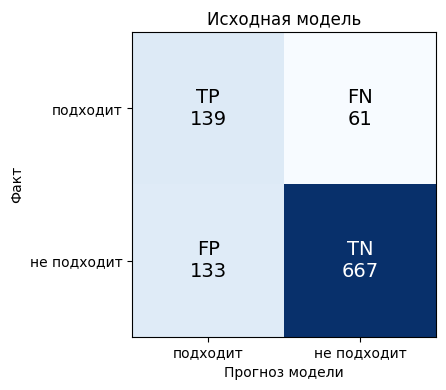

In [1]:
import numpy as np, math
import matplotlib.pyplot as plt

def draw(TP, FN, FP, TN, title):
    cm = np.array([[TP, FN], [FP, TN]])
    names = np.array([['TP', 'FN'], ['FP', 'TN']])
    fig, ax = plt.subplots(figsize=(4.6, 4))
    ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{names[i,j]}\n{cm[i,j]}', ha='center', va='center', fontsize=14,
                    color='white' if cm[i, j] > cm.max()/2 else 'black')
    ax.set_xticks([0, 1], ['подходит', 'не подходит'])
    ax.set_yticks([0, 1], ['подходит', 'не подходит'])
    ax.set_xlabel('Прогноз модели'); ax.set_ylabel('Факт'); ax.set_title(title)
    plt.tight_layout(); plt.show()

TP, FN, FP, TN = 139, 61, 133, 667
draw(TP, FN, FP, TN, 'Исходная модель')

## 2. Что означает каждая ячейка

- **TP = 139** — подходящий кандидат, модель его пропустила дальше. Рекрутер получил нужное резюме.
- **FN = 61** — подходящий кандидат, но модель его отсеяла. Компания теряет хорошего человека.
- **FP = 133** — неподходящий кандидат, но модель его пропустила. Рекрутер тратит время на лишнее резюме или собеседование.
- **TN = 667** — неподходящий кандидат, и модель его правильно отсеяла.

## 3. Метрики с подстановкой

- Accuracy = (TP+TN)/(TP+TN+FP+FN) = (139+667)/(139+667+133+61) = 806/1000 = **0.806**
- Precision = TP/(TP+FP) = 139/(139+133) = 139/272 = **0.511**
- Recall = TP/(TP+FN) = 139/(139+61) = 139/200 = **0.695**
- Specificity = TN/(TN+FP) = 667/(667+133) = 667/800 = **0.834**
- F1 = 2·P·R/(P+R) = 2·139/(2·139+133+61) = 278/472 = **0.589**

In [2]:
def metrics(TP, FN, FP, TN):
    n = TP + FN + FP + TN
    acc = (TP + TN) / n
    p = TP / (TP + FP)
    rc = TP / (TP + FN)
    sp = TN / (TN + FP)
    f1 = 2 * p * rc / (p + rc)
    mcc = (TP*TN - FP*FN) / math.sqrt((TP+FP)*(TP+FN)*(TN+FP)*(TN+FN))
    ba = (rc + sp) / 2
    return dict(accuracy=acc, precision=p, recall=rc, specificity=sp, F1=f1, MCC=mcc, balanced_acc=ba)

m1 = metrics(TP, FN, FP, TN)
for k, v in m1.items():
    print(f'{k:13s} {v:.3f}')

accuracy      0.806
precision     0.511
recall        0.695
specificity   0.834
F1            0.589
MCC           0.475
balanced_acc  0.764


## 4. Модель «всегда нет»

Такая модель отклоняет всех: TP = 0, FP = 0, FN = 200, TN = 800.
Accuracy = (0+800)/1000 = **0.800**, у нашей модели **0.806**.

**Вывод.** Разница всего 0.006: бесполезная модель, которая не находит ни одного подходящего кандидата, почти не уступает нашей по accuracy. Причина в дисбалансе классов: неподходящих резюме 80%. Поэтому в этом сценарии accuracy доверять нельзя, надо смотреть на precision, recall, F1 и MCC. У модели «всегда нет» recall = 0.

In [3]:
print('accuracy модели «всегда нет»:', (0 + 800) / 1000)

accuracy модели «всегда нет»: 0.8


## 5. Какая ошибка дороже

**FN дороже.** Пропущенный подходящий кандидат — это потерянный сотрудник, и вернуть его обычно нельзя. Ложное срабатывание (FP) стоит лишь времени рекрутера на просмотр лишнего резюме, и это можно поправить на следующем этапе отбора. Поэтому нужно максимизировать **recall** (полноту), при этом следя, чтобы precision не падал слишком сильно (например, по F1).

*Оговорка:* если рекрутеров очень мало, а откликов тысячи, то весом становится и FP, и тогда разумнее ориентироваться на F1. В ответе стоит прямо назвать выбранное допущение.

## 6. Сдвиг порога: 46 FN → TP, 171 TN → FP

- TP = 139 + 46 = **185**
- FN = 61 − 46 = **15**
- FP = 133 + 171 = **304**
- TN = 667 − 171 = **496**

Сумма снова 1000.

| Метрика | Было | Стало |
|---|---|---|
| Precision | 0.511 (139/272) | **0.378** (185/489) |
| Recall | 0.695 (139/200) | **0.925** (185/200) |
| F1 | 0.589 | **0.537** (370/689) |

**Стала ли модель лучше?** Recall вырос с 0.695 до 0.925: теряем лишь 15 подходящих кандидатов вместо 61. Precision упал с 0.511 до 0.378: теперь из пропущенных моделью резюме подходит лишь около 38%, а рекрутеры разбирают 304 лишних резюме вместо 133. F1 снизился (0.589 → 0.537).

Если, как в п. 5, главное — не терять хороших кандидатов, то для сценария модель **стала лучше по главной метрике (recall)**, но заплатили мы нагрузкой на рекрутеров. Если же нагрузка критична, то по F1 первая модель сбалансированнее. Вывод зависит от цены FP, и это надо явно написать в ответе.

Новая матрица: 185 15 304 496 сумма = 1000


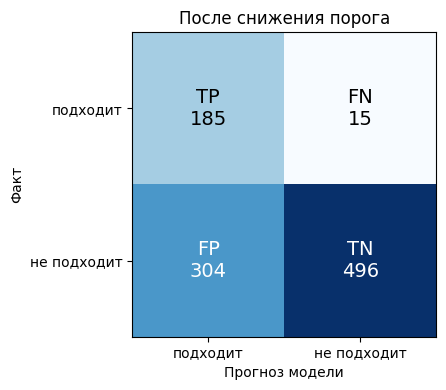

precision  было 0.511 -> стало 0.378
recall     было 0.695 -> стало 0.925
F1         было 0.589 -> стало 0.537


In [4]:
TP2, FN2, FP2, TN2 = TP + 46, FN - 46, FP + 171, TN - 171
print('Новая матрица:', TP2, FN2, FP2, TN2, 'сумма =', TP2 + FN2 + FP2 + TN2)
draw(TP2, FN2, FP2, TN2, 'После снижения порога')
m2 = metrics(TP2, FN2, FP2, TN2)
for k in ['precision', 'recall', 'F1']:
    print(f'{k:10s} было {m1[k]:.3f} -> стало {m2[k]:.3f}')

## 7. Проверка через scikit-learn (продвинутый уровень)

Восстанавливаем `y_true` и `y_pred` из матрицы. Положительный класс = 1. Важно: sklearn возвращает матрицу в порядке `[[TN, FP], [FN, TP]]`.

In [5]:
from sklearn.metrics import confusion_matrix, classification_report

def restore(TP, FN, FP, TN):
    y_true = np.array([1]*TP + [1]*FN + [0]*FP + [0]*TN)
    y_pred = np.array([1]*TP + [0]*FN + [1]*FP + [0]*TN)
    return y_true, y_pred

y_true, y_pred = restore(TP, FN, FP, TN)
cm = confusion_matrix(y_true, y_pred)
print('sklearn [[TN, FP], [FN, TP]]:\n', cm)
tn, fp, fn, tp = cm.ravel()
assert (tp, fn, fp, tn) == (TP, FN, FP, TN)
print(classification_report(y_true, y_pred, digits=3,
                            target_names=['не подходит', 'подходит']))

sklearn [[TN, FP], [FN, TP]]:
 [[667 133]
 [ 61 139]]
              precision    recall  f1-score   support

 не подходит      0.916     0.834     0.873       800
    подходит      0.511     0.695     0.589       200

    accuracy                          0.806      1000
   macro avg      0.714     0.764     0.731      1000
weighted avg      0.835     0.806     0.816      1000



In [6]:
y_true2, y_pred2 = restore(TP2, FN2, FP2, TN2)
print(confusion_matrix(y_true2, y_pred2))
print(classification_report(y_true2, y_pred2, digits=3,
                            target_names=['не подходит', 'подходит']))

[[496 304]
 [ 15 185]]
              precision    recall  f1-score   support

 не подходит      0.971     0.620     0.757       800
    подходит      0.378     0.925     0.537       200

    accuracy                          0.681      1000
   macro avg      0.674     0.772     0.647      1000
weighted avg      0.852     0.681     0.713      1000



## 8. MCC и balanced accuracy

Исходная модель:
- MCC = (TP·TN − FP·FN) / √((TP+FP)(TP+FN)(TN+FP)(TN+FN)) = (139·667 − 133·61) / √(272·200·800·728) = (92713 − 8113) / √31 683 200 000 = 84600 / 177 996 = **0.475**
- Balanced accuracy = (Recall + Specificity)/2 = (0.695 + 0.834)/2 = **0.764**

Модель после сдвига порога:
- MCC = (185·496 − 304·15) / √(489·200·800·511) = 87200 / 199 952 = **0.436**
- Balanced accuracy = (0.925 + 0.620)/2 = **0.7725** (при округлении до трёх знаков: 0.773 по школьному правилу, sklearn печатает 0.772)

In [7]:
from sklearn.metrics import matthews_corrcoef, balanced_accuracy_score, accuracy_score, f1_score

for name, (yt, yp), mm in [('исходная', (y_true, y_pred), m1), ('после сдвига', (y_true2, y_pred2), m2)]:
    print(name)
    print(f"  MCC:           вручную {mm['MCC']:.3f}   sklearn {matthews_corrcoef(yt, yp):.3f}")
    print(f"  balanced acc:  вручную {mm['balanced_acc']:.3f}   sklearn {balanced_accuracy_score(yt, yp):.3f}")

# модель «всегда нет» для сравнения
yt = y_true; yp0 = np.zeros_like(yt)
print('\n«всегда нет»: accuracy', accuracy_score(yt, yp0),
      '| F1', f1_score(yt, yp0, zero_division=0),
      '| MCC', matthews_corrcoef(yt, yp0),
      '| balanced acc', balanced_accuracy_score(yt, yp0))

исходная
  MCC:           вручную 0.475   sklearn 0.475
  balanced acc:  вручную 0.764   sklearn 0.764
после сдвига
  MCC:           вручную 0.436   sklearn 0.436
  balanced acc:  вручную 0.772   sklearn 0.772

«всегда нет»: accuracy 0.8 | F1 0.0 | MCC 0.0 | balanced acc 0.5


## 9. Какая метрика честнее всего

| Модель | Accuracy | F1 | MCC | Balanced acc. |
|---|---|---|---|---|
| «всегда нет» | 0.800 | 0.000 | 0.000 | 0.500 |
| исходная | 0.806 | 0.589 | 0.475 | 0.764 |
| после сдвига порога | 0.681 | 0.537 | 0.436 | 0.7725 |

- **Accuracy** — самая нечестная: «глупая» модель получает 0,800, почти как наша, а после сдвига порога accuracy падает до 0.681, хотя модель находит гораздо больше подходящих кандидатов. Она не различает типы ошибок и зависит от дисбаланса.
- **F1** учитывает precision и recall, но игнорирует TN, поэтому не видит, насколько хорошо отсеиваются неподходящие.
- **MCC** использует все четыре ячейки сразу и корректно работает при дисбалансе: у «всегда нет» он равен 0, то есть метрика прямо говорит «модель не лучше случайной». Поэтому MCC **честнее всего** описывает модель.
- **Balanced accuracy** тоже устойчива к дисбалансу (у «всегда нет» она равна 0,5).

Оговорка: MCC симметрична и не знает, что FN дороже FP. Поэтому при выборе между моделями из п. 6 MCC даёт общее качество (оно у исходной выше: 0.475 против 0.436), а решающим для сценария остаётся recall из п. 5.